In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px

adat = pd.read_csv("penguins_size.csv")
display(adat.head(5))

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [5]:
print("Hiányzó adatok száma:")
print(adat.isnull().sum())
adat = adat.dropna()
print(f"\nA tisztított adathalmaz mérete: {adat.shape[0]} sor")

Hiányzó adatok száma:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

A tisztított adathalmaz mérete: 334 sor


In [6]:
print("--- 1.Kérdés: Milyen alapstatisztikák jellemzik a pingvinek testtömegét a teljes populációban? ---")

atlag_tomeg = np.mean(adat["body_mass_g"])
median_tomeg = np.median(adat["body_mass_g"])
szoras_tomeg = np.std(adat["body_mass_g"])

print(f"Átlagos testtömeg: {atlag_tomeg:.2f} g")
print(f"Medián testtömeg: {median_tomeg:.2f} g")
print(f"Szórás: {szoras_tomeg:.2f} g")

--- 1.Kérdés: Testtömeg alapstatisztikák ---
Átlagos testtömeg: 4209.06 g
Medián testtömeg: 4050.00 g
Szórás: 803.63 g


--- 2.Kérdés: Melyik pingvinfaj rendelkezik a legnagyobb átlagos testtömeggel? ---


,species,body_mass_g
0,Adelie,3706.164384
1,Chinstrap,3733.088235
2,Gentoo,5090.625000


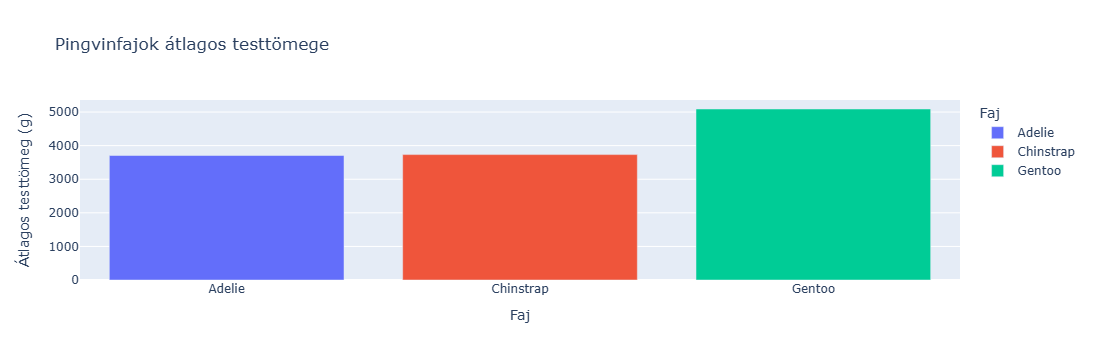

In [7]:
print("--- 2.Kérdés: Melyik pingvinfaj rendelkezik a legnagyobb átlagos testtömeggel? ---")

faj_tomeg = adat.groupby("species")["body_mass_g"].mean().reset_index()
display(faj_tomeg)

fig1 = px.bar(
    faj_tomeg,
    x="species",
    y="body_mass_g",
    title="Pingvinfajok átlagos testtömege",
    labels={"species": "Faj", "body_mass_g": "Átlagos testtömeg (g)"},
    color="species",
)
fig1.show()

In [8]:
print("--- 3.Kérdés: Van-e különbség a hímek és a nőstények csőrhossza között? ---")

nem_csor = adat.groupby("sex")["culmen_length_mm"].mean().reset_index()
display(nem_csor)

--- 3. KÉRDÉS: Van-e különbség a hímek és a nőstények csőrhossza között? ---


,sex,culmen_length_mm
0,.,44.500000
1,FEMALE,42.096970
2,MALE,45.854762


--- 4.Kérdés: Melyik szigeten milyen fajok élnek és mekkora egyedszámban? ---


,island,species,count
0,Biscoe,Adelie,44
1,Biscoe,Gentoo,120
2,Dream,Adelie,55
3,Dream,Chinstrap,68
4,Torgersen,Adelie,47


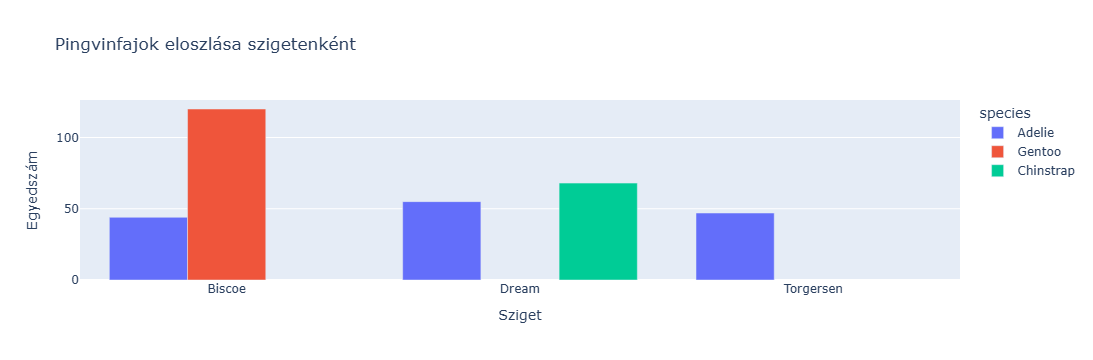

In [9]:
print("--- 4.Kérdés: Melyik szigeten milyen fajok élnek és mekkora egyedszámban? ---")

sziget_faj = (
    adat.groupby(["island", "species"]).size().reset_index(name="count")
)
display(sziget_faj)

fig2 = px.bar(
    sziget_faj,
    x="island",
    y="count",
    color="species",
    barmode="group",
    title="Pingvinfajok eloszlása szigetenként",
    labels={"island": "Sziget", "count": "Egyedszám"},
)
fig2.show()

--- 5.Kérdés: Függ-e egymástól az úszószárny hossza és a testtömeg? ---
Korrelációs együttható: 0.87


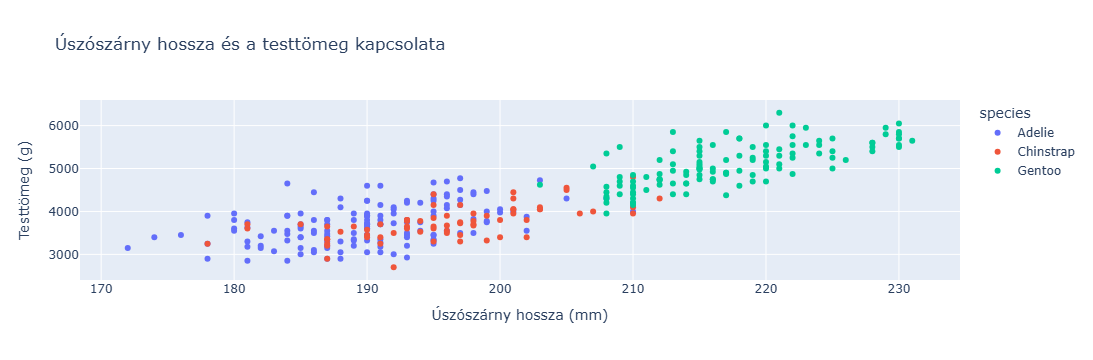

In [11]:
print("--- 5.Kérdés: Függ-e egymástól az úszószárny hossza és a testtömeg? ---")

korrelacio = adat["flipper_length_mm"].corr(adat["body_mass_g"])
print(f"Korrelációs együttható: {korrelacio:.2f}")


fig3 = px.scatter(
    adat,
    x="flipper_length_mm",
    y="body_mass_g",
    color="species",
    title="Úszószárny hossza és a testtömeg kapcsolata",
    labels={
        "flipper_length_mm": "Úszószárny hossza (mm)",
        "body_mass_g": "Testtömeg (g)",
    },
)
fig3.show()